In [1]:
!apt-get install aria2 -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libaria2-0 libc-ares2
The following NEW packages will be installed:
  aria2 libaria2-0 libc-ares2
0 upgraded, 3 newly installed, 0 to remove and 123 not upgraded.
Need to get 1,513 kB of archives.
After this operation, 5,441 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 libc-ares2 amd64 1.18.1-1ubuntu0.22.04.3 [45.1 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libaria2-0 amd64 1.36.0-1 [1,086 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 aria2 amd64 1.36.0-1 [381 kB]
Fetched 1,513 kB in 1s (1,357 kB/s)
Selecting previously unselected package libc-ares2:amd64.
(Reading database ... 129073 files and directories currently installed.)
Preparing to unpack .../libc-ares2_1.18.1-1ubuntu0.22.04.3_amd64.deb ...
Unpacking libc-ares2:amd64 (1.18.1-1ubu

In [2]:
!aria2c -x 16 -s 16 "https://zenodo.org/records/6254739/files/noise_2Q_-2.51dBSNR_490x490x6000.tif?download=1"
!aria2c -x 16 -s 16 "https://zenodo.org/records/6254739/files/clean_30Hz_490x490x6000.tif?download=1"



03/24 05:58:41 [NOTICE] Downloading 1 item(s)
 *** Download Progress Summary as of Tue Mar 24 05:59:45 2026 ***              11s]mm0m
[#209624 2.2GiB/2.7GiB(82%) CN:16 DL:26MiB ETA:18s]
FILE: /kaggle/working/noise_2Q_-2.51dBSNR_490x490x6000.tif
-------------------------------------------------------------------------------

[#209624 2.7GiB/2.7GiB(99%) CN:1 DL:5.8MiB]0m]m
03/24 06:00:17 [NOTICE] Download complete: /kaggle/working/noise_2Q_-2.51dBSNR_490x490x6000.tif

Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
209624|OK  |    29MiB/s|/kaggle/working/noise_2Q_-2.51dBSNR_490x490x6000.tif

Status Legend:
(OK):download completed.

03/24 06:00:17 [NOTICE] Downloading 1 item(s)
[#30581d 2.7GiB/2.7GiB(99%) CN:2 DL:198MiB]m0m]m
03/24 06:00:44 [NOTICE] Download complete: /kaggle/working/clean_30Hz_490x490x6000.tif

Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+====================

Running ViT-UNet
Running STAU-Net
Running DeepCAD
Running DnCNN


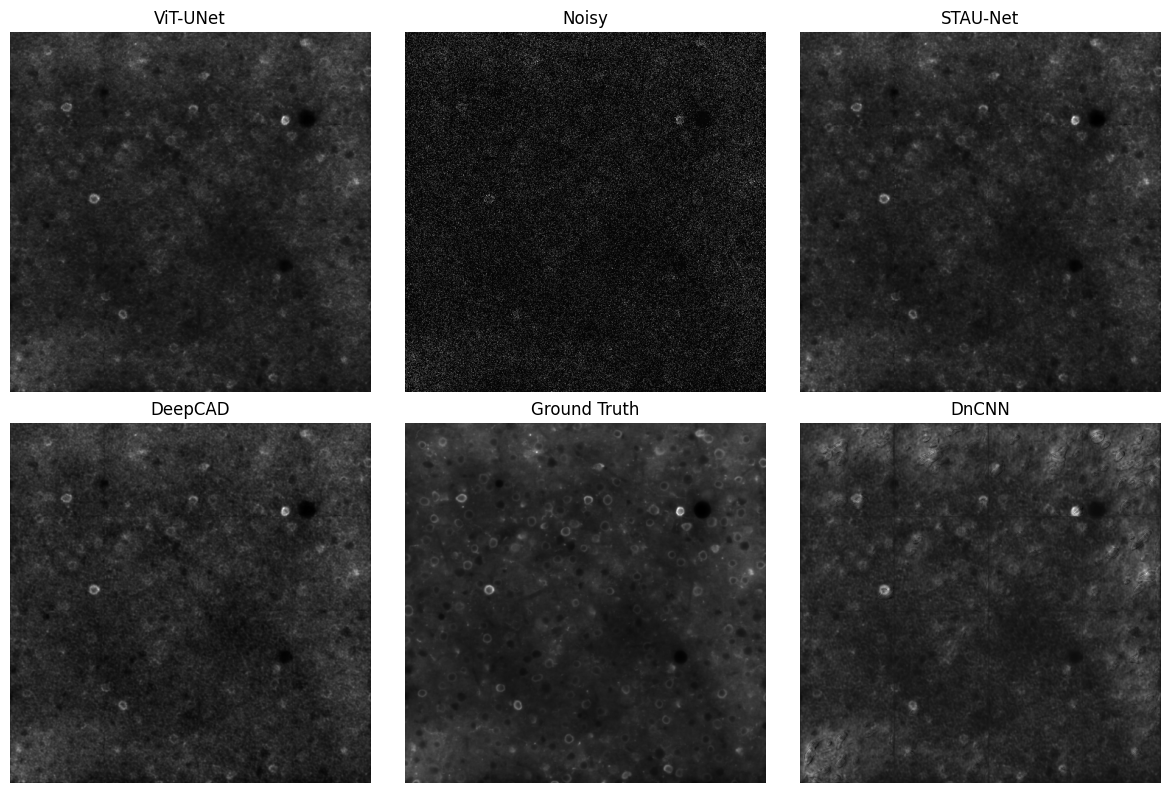

DONE


IndexError: list index out of range

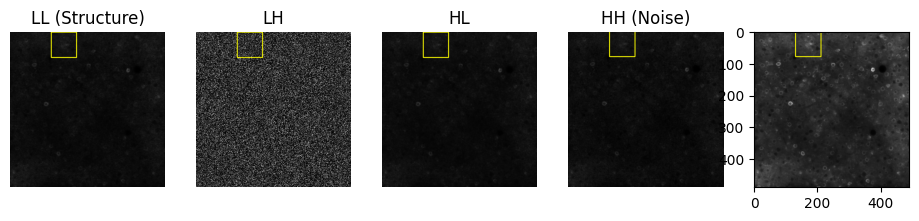

In [8]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

import sys
import torch


# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        ''' self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)'''

        with tifffile.TiffFile(noisy_path) as tif:
            self.noisy = tif.asarray(out='memmap')
        
        with tifffile.TiffFile(gt_path) as tif:
            self.gt = tif.asarray(out='memmap')
        
        self.noisy = self.noisy.astype(np.float32)
        self.gt = self.gt.astype(np.float32)

        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

import os
import numpy as np
import torch
import torch.nn.functional as F
import tifffile
import matplotlib.pyplot as plt
import gc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11
INPUT_CHANNELS = 10

VAL_DIR = "/kaggle/working/"
WEIGHTS_DIR = "/kaggle/input/datasets/siddhartharavva/trainedmodels"


HIGH_FILE  = "clean_30Hz_490x490x6000.tif"
LOW_FILE= "noise_2Q_-2.51dBSNR_490x490x6000.tif"

# ==========================
# LOAD DATA
# ==========================


# ==========================
# FAST PARTIAL LOAD (CORRECT)
# ==========================

# First open file to get total frame count
with tifffile.TiffFile(os.path.join(VAL_DIR, LOW_FILE)) as tif:
    total_frames = len(tif.pages)

half = TEMPORAL_WINDOW // 2
center = total_frames // 2

# Load only required frames (11 frames)
with tifffile.TiffFile(os.path.join(VAL_DIR, LOW_FILE)) as tif:
    noisy = tif.asarray(key=range(center-half, center+half+1)).astype(np.float32)

# Load GT center frame only
with tifffile.TiffFile(os.path.join(VAL_DIR, HIGH_FILE)) as tif:
    gt = tif.asarray(key=center).astype(np.float32)

# Normalize
noisy = noisy / (noisy.max() + 1e-8)
gt    = gt / (gt.max() + 1e-8)

FRAMES, H, W = noisy.shape

half = TEMPORAL_WINDOW // 2
center = half   # because noisy already contains only 11 frames

# Remove center frame (blind spot)
context = np.concatenate(
    (noisy[:center], noisy[center+1:]),
    axis=0
)

#context2d = torch.from_numpy(context).unsqueeze(0).float().to(DEVICE)
#context3d = torch.from_numpy(context).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
# ==========================
# MODEL LIST
# ==========================

model_configs = [

("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), "ViT_UNet_best.pth", "2D"),
("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), "STAU_Net_best.pth", "2D"),
("DeepCAD", DeepCAD_3D_UNet(in_channels=1), "DeepCAD_best.pth", "3D"),
("DnCNN", DnCNN(channels=INPUT_CHANNELS), "DnCNN_best.pth", "2D")

]

results = {}

# ==========================
# RUN MODELS
# ==========================
PATCH = 128
STRIDE = 128

def run_model_patchwise(model, mode):

    output = np.zeros((H, W), np.float32)
    count  = np.zeros((H, W), np.float32)

    for y in range(0, H, STRIDE):
        for x in range(0, W, STRIDE):

            y1 = min(y, H-PATCH)
            x1 = min(x, W-PATCH)

            patch = context[:, y1:y1+PATCH, x1:x1+PATCH]

            if mode == "3D":
                inp = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
            else:
                inp = torch.from_numpy(patch).unsqueeze(0).float().to(DEVICE)

            with torch.no_grad():

                out = model(inp)

                if mode == "3D":
                    out = out.mean(dim=2)

            out = out.squeeze().cpu().numpy()

            output[y1:y1+PATCH, x1:x1+PATCH] += out
            count[y1:y1+PATCH, x1:x1+PATCH]  += 1

    return output / np.maximum(count, 1)

for name, model, weight, mode in model_configs:

    print("Running", name)
    state = torch.load(
        os.path.join(WEIGHTS_DIR, weight),
        map_location="cpu",   # FORCE CPU FIRST
        weights_only=False    # IMPORTANT
    )
    
    # Extract actual state_dict
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    
    # Remove DataParallel prefix
    clean = {k.replace("module.", ""): v for k, v in state.items()}
    
    model.load_state_dict(clean, strict=False)
    model.to(DEVICE)
    model.eval()

    results[name] = run_model_patchwise(model, mode)

    del model
    torch.cuda.empty_cache()
    gc.collect()
    
# ==========================
# SHOW GRID
# ==========================

plt.figure(figsize=(12,8))

names = list(results.keys())

plt.subplot(2,3,1)
plt.imshow(results[names[0]], cmap="gray")
plt.title(names[0])
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(noisy[center], cmap="gray")
plt.title("Noisy")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(results[names[1]], cmap="gray")
plt.title(names[1])
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(results[names[2]], cmap="gray")
plt.title(names[2])
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(gt, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(results[names[3]], cmap="gray")
plt.title(names[3])
plt.axis("off")

plt.tight_layout()
plt.savefig("MODEL_COMPARISON_FIXE1.png", dpi=300)
plt.show()

print("DONE")

# ==========================
# WAVELET ANALYSIS (ADD HERE)
# ==========================
import pywt
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ==========================
# CONFIG
# ==========================

USE_ROI = True  # set False if you want full image

# If using ROI (you already computed these)
# roi_x, roi_y, roi_w, roi_h should already exist

# ==========================
# HELPERS
# ==========================

def wavelet_decompose(img):
    LL, (LH, HL, HH) = pywt.dwt2(img, 'haar')

    # Resize to original size for consistent display
    H, W = img.shape
    LL = cv2.resize(np.abs(LL), (W, H))
    LH = cv2.resize(np.abs(LH), (W, H))
    HL = cv2.resize(np.abs(HL), (W, H))
    HH = cv2.resize(np.abs(HH), (W, H))

    return LL, LH, HL, HH


def normalize_global(band_list):
    all_vals = np.concatenate([b.flatten() for b in band_list])
    min_val, max_val = all_vals.min(), all_vals.max()

    return [(b - min_val) / (max_val - min_val + 1e-8) for b in band_list]


def crop(img):
    if not USE_ROI:
        return img
    return img[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w]


# ==========================
# PREPARE IMAGES
# ==========================

wavelet_images = {
    "ViT-UNet": crop(results["ViT-UNet"]),
    "Noisy": crop(noisy[center]),
    "STAU-Net": crop(results["STAU-Net"]),
    "DeepCAD": crop(results["DeepCAD"]),
    "Ground Truth": crop(gt),
    "DnCNN": crop(results["DnCNN"])
}

names = list(wavelet_images.keys())
num_models = len(names)


# ==========================
# VISUALIZATION WITH ZOOM
# ==========================

import cv2

# Choose a meaningful region (YOU CAN CHANGE THIS)
roi_x, roi_y = W//2 - 40, H//2 - 40
roi_w, roi_h = 80, 80
zoom_scale = 3

def draw_box(img):
    img_box = img.copy()
    img_box = (img_box * 255).astype(np.uint8)
    img_box = cv2.cvtColor(img_box, cv2.COLOR_GRAY2RGB)
    cv2.rectangle(img_box, (roi_x, roi_y), (roi_x+roi_w, roi_y+roi_h), (255,255,0), 2)
    return img_box

def get_zoom(img):
    roi = img[roi_y:roi_y+roi_h, roi_x:roi_x+roi_w]
    zoom = cv2.resize(roi, None, fx=zoom_scale, fy=zoom_scale, interpolation=cv2.INTER_NEAREST)
    return zoom

# Prepare images
images = {
    "ViT-UNet": results["ViT-UNet"],
    "Noisy": noisy[center],
    "STAU-Net": results["STAU-Net"],
    "DeepCAD": results["DeepCAD"],
    "Ground Truth": gt,
    "DnCNN": results["DnCNN"]
}

error_map = np.abs(results["ViT-UNet"] - gt)

# Smooth it a bit
import cv2
error_map_blur = cv2.GaussianBlur(error_map, (21,21), 0)

# Find highest error location
y, x = np.unravel_index(np.argmax(error_map_blur), error_map_blur.shape)

# Center ROI around it
roi_x = max(0, x - 40)
roi_y = max(0, y - 40)
roi_w, roi_h = 80, 80
var_map = cv2.Laplacian(gt, cv2.CV_32F)
var_map = np.abs(var_map)

y, x = np.unravel_index(np.argmax(var_map), var_map.shape)

roi_x = max(0, x - 40)
roi_y = max(0, y - 40)

combined = error_map_blur + var_map
y, x = np.unravel_index(np.argmax(combined), combined.shape)
# Plot
plt.figure(figsize=(14,6))

# --- TOP ROW (with boxes) ---
for i, (name, img) in enumerate(images.items()):
    plt.subplot(2, 6, i+1)
    plt.imshow(draw_box(img))
    plt.title(titles[i])
    plt.axis("off")

# --- BOTTOM ROW (zoomed) ---
for i, (name, img) in enumerate(images.items()):
    plt.subplot(2, 6, i+7)
    plt.imshow(get_zoom(img), cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.savefig("MODEL_COMPARISON_ZOOM.png", dpi=300)
plt.show()

# ==========================
# COMPUTE ALL WAVELETS FIRST
# ==========================

LL_list, LH_list, HL_list, HH_list = [], [], [], []

for name in names:
    LL, LH, HL, HH = wavelet_decompose(wavelet_images[name])
    LL_list.append(LL)
    LH_list.append(LH)
    HL_list.append(HL)
    HH_list.append(HH)

# ==========================
# GLOBAL NORMALIZATION (KEY FIX)
# ==========================

LL_list = normalize_global(LL_list)
LH_list = normalize_global(LH_list)
HL_list = normalize_global(HL_list)
HH_list = normalize_global(HH_list)

# ==========================
# PLOT
# ==========================

fig, axes = plt.subplots(num_models, 4, figsize=(12, 2*num_models))

titles = ["LL (Structure)", "LH", "HL", "HH (Noise)"]

for i, name in enumerate(names):

    bands = [LL_list[i], LH_list[i], HL_list[i], HH_list[i]]

    for j in range(4):
        axes[i, j].imshow(bands[j], cmap='gray')
        axes[i, j].axis("off")

        if i == 0:
            axes[i, j].set_title(titles[j], fontsize=10)

    axes[i, 0].set_ylabel(name, fontsize=10)

plt.tight_layout()
plt.savefig("WAVELET_COMPARISON_FIXED.png", dpi=300)
plt.show()


In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = True

print("Using GPU:", torch.cuda.get_device_name(0))

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        '''
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        '''
        with tifffile.TiffFile(noisy_path) as tif:
            self.noisy = tif.asarray(out='memmap')
        
        with tifffile.TiffFile(gt_path) as tif:
            self.gt = tif.asarray(out='memmap')
        
        self.noisy = self.noisy.astype(np.float32)
        self.gt = self.gt.astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. METRIC CALCULATION
# =========================================================================
def evaluate_model_on_file(model, noisy_file, gt_file, mode='2.5D', batch_size=32):
    ds = PairedValidationDataset(noisy_file, gt_file, mode=mode)
    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True
    )    
    model.eval()
    total_psnr = 0
    total_ssim = 0
    count = 0
    
    # Warmup
    try:
        dummy = next(iter(loader))[0].to(DEVICE)
        with torch.no_grad(): _ = model(dummy)
    except StopIteration: return 0, 0, 0

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)
    total_inference_time_ms = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            start_event.record()
            outputs = model(inputs)
            end_event.record()
            torch.cuda.synchronize()
            
            total_inference_time_ms += start_event.elapsed_time(end_event)
            
            # --- Handle Output Shapes ---
            if mode == '3D':
                # DeepCAD output (B, 1, 10, H, W) -> Collapse to (B, 1, H, W)
                outputs = outputs.mean(dim=2)
            
            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()
            
            if len(out_np.shape) == 2:
                out_np = out_np[None, ...]
                tgt_np = tgt_np[None, ...]
            
            for b in range(out_np.shape[0]):
                p = psnr(tgt_np[b], out_np[b], data_range=1.0)
                s = ssim(tgt_np[b], out_np[b], data_range=1.0)
                total_psnr += p
                total_ssim += s
                count += 1
                
    if count == 0: return 0, 0, 0
    
    return total_psnr / count, total_ssim / count, total_inference_time_ms / 1000.0

# =========================================================================
# 3. MAIN EVALUATION LOOP
# =========================================================================
VAL_DIR = "/kaggle/working/"
gt_path = os.path.join(VAL_DIR, "clean_30Hz_490x490x6000.tif")
files_to_test = ["/kaggle/working/noise_2Q_-2.51dBSNR_490x490x6000.tif"]
WEIGHTS_DIR = "/kaggle/input/datasets/siddhartharavva/trainedmodels"


# NOTE: We initialize models with INPUT_CHANNELS (10), not TEMPORAL_WINDOW (11)
model_configs = [
    ("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")),
    ("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")),
    ("DeepCAD", DeepCAD_3D_UNet(in_channels=1), '3D', os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")),
    ("DnCNN", DnCNN(channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "DnCNN_best.pth"))
]

results_data = []

print("\n=== STARTING EVALUATION SUITE ===")

for model_name, model_inst, mode, weight_path in model_configs:
    print(f"\nLoading {model_name}...")
    try:

        
        state_dict = torch.load(weight_path, map_location=DEVICE)

        # Remove "module." prefix if present
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("module."):
                new_state_dict[k[7:]] = v
            else:
                new_state_dict[k] = v
        
        model_inst.load_state_dict(new_state_dict)
        
        model_inst.to(DEVICE)
        
        for fname in files_to_test:
            noisy_path = os.path.join(VAL_DIR, fname)
            if not os.path.exists(noisy_path): continue
            
            p, s, t = evaluate_model_on_file(model_inst, noisy_path, gt_path, mode=mode)
            print(f"  -> {fname}: PSNR={p:.2f} | SSIM={s:.4f} | Time={t:.4f}s")
            results_data.append([model_name, fname, round(p, 4), round(s, 4), round(t, 4)])
        
        del model_inst
        torch.cuda.empty_cache()
        
    except Exception as e:
        print(f"Error loading/running {model_name}: {e}")
1
# Save CSV
csv_filename = "validation_results.csv"
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Model", "File", "PSNR (dB)", "SSIM", "Runtime (s)"])
    writer.writerows(results_data)

print(f"\n>>> Done. Results saved to {csv_filename}")

In [ ]:
import os

for file in os.listdir("/kaggle/working"):
    if file.endswith(".tif"):
        os.remove(os.path.join("/kaggle/working", file))

In [ ]:
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
image_paths = {
    "ViT-UNet": "vit.png",
    "Noisy": "noisy.png",
    "STAU-Net": "stau.png",
    "DeepCAD": "deepcad.png",
    "Ground Truth": "gt.png",
    "DnCNN": "dncnn.png"
}

# ---------- HELPERS ----------
def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Image not found: {path}")
    return img.astype(np.float32)

def normalize(img):
    return (img - img.min()) / (img.max() - img.min() + 1e-8)

def wavelet_decompose(img):
    coeffs2 = pywt.dwt2(img, 'haar')
    LL, (LH, HL, HH) = coeffs2
    return LL, LH, HL, HH

# ---------- MAIN ----------
images = {name: load_image(path) for name, path in image_paths.items()}

rows = len(images)
cols = 4

fig, axes = plt.subplots(rows, cols, figsize=(12, 2 * rows))

for i, (name, img) in enumerate(images.items()):
    LL, LH, HL, HH = wavelet_decompose(img)

    bands = [LL, LH, HL, HH]
    titles = ["LL (Structure)", "LH", "HL", "HH (Noise)"]

    for j in range(cols):
        axes[i, j].imshow(normalize(bands[j]), cmap='gray')
        axes[i, j].axis('off')

        if i == 0:
            axes[i, j].set_title(titles[j], fontsize=10)

    axes[i, 0].set_ylabel(name, fontsize=10)

plt.tight_layout()
plt.savefig("wavelet_comparison.png", dpi=300)
plt.show()